In [1]:
import matplotlib.pyplot as plt 
import uproot
import numpy as np

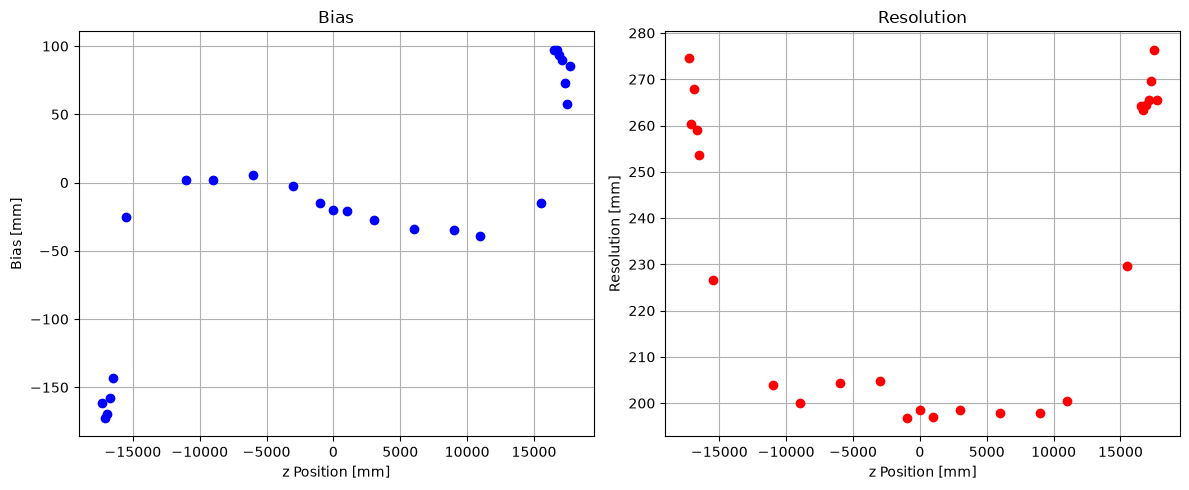

In [2]:
file = uproot.open("output3.root")
bias = file["bias"]    
res = file["resolution"]

x = bias.member("fX")
b = bias.member("fY")
b_err = bias.member("fEY")


r= res.member("fY")
r_err = res.member("fEY")

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].errorbar(x, b, fmt='o', label='Bias', color='blue')
ax[0].set_xlabel('z Position [mm]')
ax[0].set_ylabel('Bias [mm]')
ax[0].set_title('Bias')
ax[0].grid()

ax[1].errorbar(x, r, fmt='o', label='Resolution', color='red')
ax[1].set_xlabel('z Position [mm]')
ax[1].set_ylabel('Resolution [mm]')
ax[1].set_title('Resolution')
ax[1].grid()
plt.tight_layout()
plt.show()



Chi2 ridotto: 0.9896


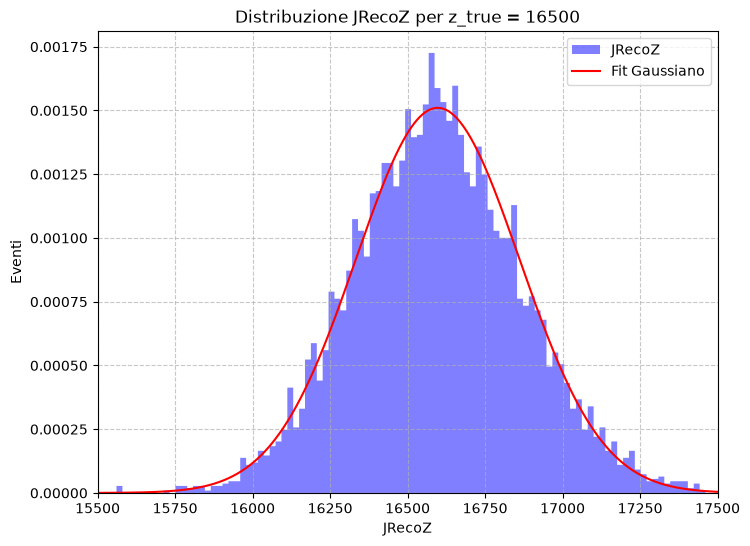

In [16]:
file = uproot.open("output4.root")

bias = file["bias"]    
res = file["resolution"]

b = bias.member("fY")
r= res.member("fY")

mu= b[18]+16500
sigma= r[18]


if "z_16500;1" in file.keys():
    fig1, ax1 = plt.subplots(figsize=(8, 6))
    
    # Estraiamo l'istogramma
    hist = file["z_16500"]
    
    # uproot ha un comodo metodo to_numpy() che restituisce gli accessi (counts) e i bordi dei bin (edges)
    counts, edges = hist.to_numpy()
    bin_width = edges[1] - edges[0]
    total_events = np.sum(counts)
    counts_norm = counts / (total_events * bin_width)

    x_fit = np.linspace(15500, 17500, 1000)
    y_fit = 1/(sigma*np.sqrt(2*np.pi)) * np.exp(-0.5 * ((x_fit - mu)/sigma)**2)
    
    # Disegniamo l'istogramma
    ax1.stairs(counts_norm, edges, fill=True, alpha=0.5, color='blue', label='JRecoZ')
    ax1.set_xlim(15500, 17500)
    ax1.set_title("Distribuzione JRecoZ per z_true = 16500")
    ax1.set_xlabel("JRecoZ")
    ax1.set_ylabel("Eventi")
    ax1.grid(True, linestyle='--', alpha=0.7)

    ax1.plot(x_fit, y_fit, color='red', label='Fit Gaussiano')
    
    ax1.legend()

    print(f"Chi2 ridotto: {0.9896}")